In [1]:

import pandas as pd
import numpy as np

# Load the datasets
train = pd.read_csv("UNSW_NB15_training-set.csv")
test = pd.read_csv("UNSW_NB15_testing-set.csv")

# Display dataset dimensions
print("Training shape:", train.shape)
print("Testing shape:", test.shape)

# Display columns
print("\nColumns:")
print(train.columns.tolist())

# Display class distributions
print("\nTraining label distribution:")
print(train["label"].value_counts())

print("\nTesting label distribution:")
print(test["label"].value_counts())

# Check missing values
print("\nMissing values in training:", train.isnull().sum().sum())
print("Missing values in testing:", test.isnull().sum().sum())

# Preview records
display(train.head())


Training shape: (175341, 45)
Testing shape: (82332, 45)

Columns:
['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']

Training label distribution:
label
1    119341
0     56000
Name: count, dtype: int64

Testing label distribution:
label
1    45332
0    37000
Name: count, dtype: int64

Missing values in training: 0
Missing values in testing: 0


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


In [2]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import IsolationForest
from sklearn.metrics import confusion_matrix, classification_report

# Keep only benign traffic for training
train_benign = train[train["label"] == 0].copy()

# Keep both benign and attack traffic for testing
test_data = test.copy()

# Remove identifiers and labels from model features
excluded_columns = ["id", "attack_cat", "label"]

feature_columns = [
    col for col in train.columns
    if col not in excluded_columns
]

# Identify categorical and numerical features
categorical_features = ["proto", "service", "state"]

numerical_features = [
    col for col in feature_columns
    if col not in categorical_features
]

print("Benign training records:", len(train_benign))
print("Testing records:", len(test_data))

print("\nCategorical features:", categorical_features)
print("Numerical features:", len(numerical_features))

print("\nTotal model features:", len(feature_columns))


Benign training records: 56000
Testing records: 82332

Categorical features: ['proto', 'service', 'state']
Numerical features: 39

Total model features: 42


In [3]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Build preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Fit preprocessing ONLY on benign training data
X_train = preprocessor.fit_transform(
    train_benign[feature_columns]
)

# Transform the test data using the same fitted preprocessor
X_test = preprocessor.transform(
    test_data[feature_columns]
)

# Extract ground-truth labels for evaluation
y_test = test_data["label"].values

print("Training matrix shape:", X_train.shape)
print("Testing matrix shape:", X_test.shape)

print("Preprocessing complete.")


Training matrix shape: (56000, 65)
Testing matrix shape: (82332, 65)
Preprocessing complete.


In [4]:

from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# Contamination values to investigate
contamination_values = [0.01, 0.03, 0.05, 0.10]

# Store experimental results
results = []

for contamination in contamination_values:

    print(f"\nRunning experiment with contamination = {contamination}")

    # Initialize model
    model = IsolationForest(
        n_estimators=200,
        contamination=contamination,
        random_state=42,
        n_jobs=-1
    )

    # Train using ONLY benign traffic
    model.fit(X_train)

    # Predict test observations
    predictions = model.predict(X_test)

    # Isolation Forest outputs:
    #  1 = inlier (normal)
    # -1 = outlier (anomaly)
    # Convert to our binary convention:
    #  0 = normal
    #  1 = anomaly
    y_pred = (predictions == -1).astype(int)

    # Ground truth:
    #  0 = normal
    #  1 = attack
    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    # Calculate evaluation metrics
    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    false_positive_rate = fp / (fp + tn)

    detection_rate = tp / (tp + fn)

    # Store results
    results.append({
        "Contamination": contamination,
        "True Negatives": tn,
        "False Positives": fp,
        "False Negatives": fn,
        "True Positives": tp,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "False Positive Rate": false_positive_rate,
        "Detection Rate": detection_rate
    })

# Display results
results_df = pd.DataFrame(results)

display(results_df.round(4))



Running experiment with contamination = 0.01

Running experiment with contamination = 0.03

Running experiment with contamination = 0.05

Running experiment with contamination = 0.1


,Contamination,True Negatives,False Positives,False Negatives,True Positives,Precision,Recall,F1 Score,False Positive Rate,Detection Rate
0,0.01,36671,329,36070,9262,0.9657,0.2043,0.3373,0.0089,0.2043
1,0.03,35906,1094,34245,11087,0.9102,0.2446,0.3855,0.0296,0.2446
2,0.05,34804,2196,31773,13559,0.8606,0.2991,0.4439,0.0594,0.2991
3,0.10,31583,5417,22499,22833,0.8082,0.5037,0.6206,0.1464,0.5037


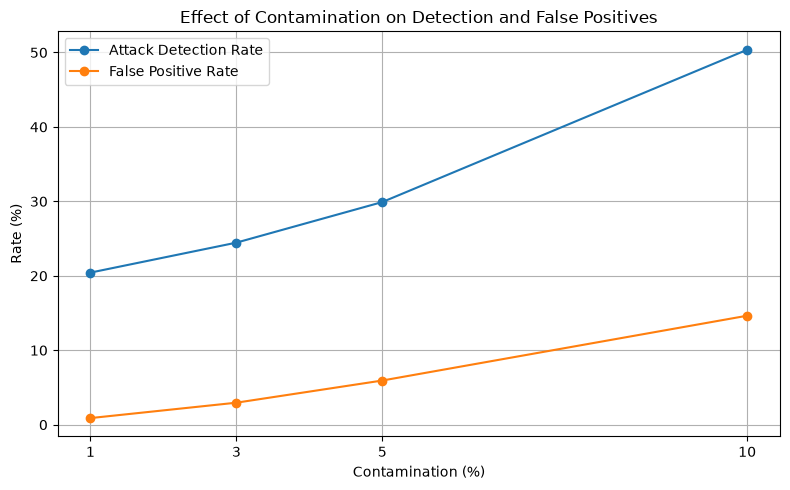

In [5]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    results_df["Contamination"] * 100,
    results_df["Detection Rate"] * 100,
    marker="o",
    label="Attack Detection Rate"
)

plt.plot(
    results_df["Contamination"] * 100,
    results_df["False Positive Rate"] * 100,
    marker="o",
    label="False Positive Rate"
)

plt.xlabel("Contamination (%)")
plt.ylabel("Rate (%)")
plt.title("Effect of Contamination on Detection and False Positives")

plt.xticks([1, 3, 5, 10])
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


In [6]:

results_df.to_csv("isolation_forest_results.csv", index=False)

print("Results saved successfully.")


Results saved successfully.


In [7]:

import pandas as pd
import numpy as np

from sklearn.ensemble import IsolationForest
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

seeds = [0, 21, 42, 123, 2025]
contamination_values = [0.01, 0.03, 0.05, 0.10]

robustness_results = []

for seed in seeds:
    for contamination in contamination_values:

        model = IsolationForest(
            n_estimators=200,
            contamination=contamination,
            random_state=seed,
            n_jobs=-1
        )

        model.fit(X_train)

        predictions = model.predict(X_test)
        y_pred = (predictions == -1).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_test, y_pred, labels=[0, 1]
        ).ravel()

        robustness_results.append({
            "Seed": seed,
            "Contamination": contamination,
            "Precision": precision_score(
                y_test, y_pred, zero_division=0
            ),
            "Detection Rate": tp / (tp + fn),
            "False Positive Rate": fp / (fp + tn),
            "F1 Score": f1_score(
                y_test, y_pred, zero_division=0
            )
        })

robustness_df = pd.DataFrame(robustness_results)

summary_df = robustness_df.groupby("Contamination").agg(
    Detection_Mean=("Detection Rate", "mean"),
    Detection_Std=("Detection Rate", "std"),
    FPR_Mean=("False Positive Rate", "mean"),
    FPR_Std=("False Positive Rate", "std"),
    Precision_Mean=("Precision", "mean"),
    F1_Mean=("F1 Score", "mean")
).reset_index()

display(summary_df.round(4))

robustness_df.to_csv("robustness_all_runs.csv", index=False)
summary_df.to_csv("robustness_summary.csv", index=False)

print("Robustness experiment completed.")


,Contamination,Detection_Mean,Detection_Std,FPR_Mean,FPR_Std,Precision_Mean,F1_Mean
0,0.01,0.2163,0.0154,0.0092,0.0013,0.9664,0.3533
1,0.03,0.2601,0.0139,0.0324,0.0031,0.9078,0.4042
2,0.05,0.3297,0.0264,0.0630,0.0026,0.8649,0.4770
3,0.10,0.5297,0.0336,0.1533,0.0093,0.8088,0.6397


Robustness experiment completed.


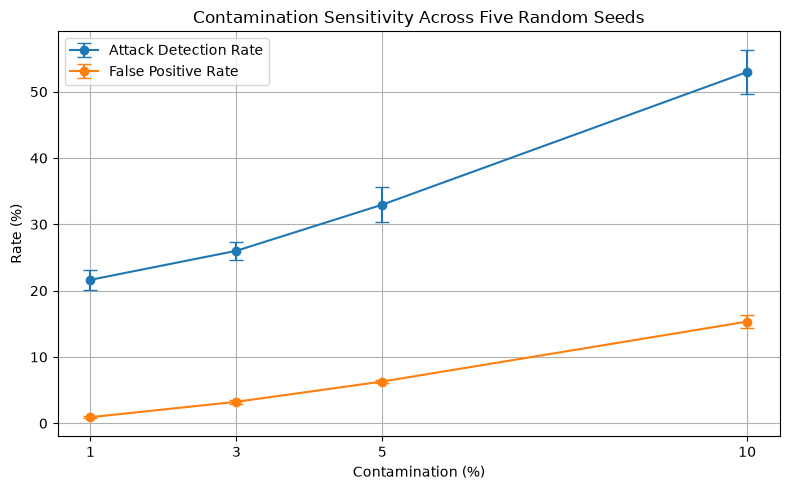

In [8]:

plt.figure(figsize=(8, 5))

contamination_percent = summary_df["Contamination"] * 100

plt.errorbar(
    contamination_percent,
    summary_df["Detection_Mean"] * 100,
    yerr=summary_df["Detection_Std"] * 100,
    marker="o",
    capsize=5,
    label="Attack Detection Rate"
)

plt.errorbar(
    contamination_percent,
    summary_df["FPR_Mean"] * 100,
    yerr=summary_df["FPR_Std"] * 100,
    marker="o",
    capsize=5,
    label="False Positive Rate"
)

plt.xlabel("Contamination (%)")
plt.ylabel("Rate (%)")
plt.title("Contamination Sensitivity Across Five Random Seeds")

plt.xticks([1, 3, 5, 10])
plt.grid(True)
plt.legend()
plt.tight_layout()

plt.savefig(
    "contamination_robustness.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [9]:

from sklearn.metrics import roc_auc_score, average_precision_score

ranking_results = []

for seed in seeds:

    model = IsolationForest(
        n_estimators=200,
        contamination=0.05,  # Does not affect score ranking
        random_state=seed,
        n_jobs=-1
    )

    model.fit(X_train)

    # Higher score = more anomalous
    anomaly_scores = -model.score_samples(X_test)

    roc_auc = roc_auc_score(y_test, anomaly_scores)

    average_precision = average_precision_score(
        y_test, anomaly_scores
    )

    ranking_results.append({
        "Seed": seed,
        "ROC-AUC": roc_auc,
        "Average Precision": average_precision
    })

ranking_df = pd.DataFrame(ranking_results)

display(ranking_df.round(4))

print("\nMean ROC-AUC:", ranking_df["ROC-AUC"].mean().round(4))
print("Mean Average Precision:", ranking_df["Average Precision"].mean().round(4))

ranking_df.to_csv("ranking_metrics.csv", index=False)


,Seed,ROC-AUC,Average Precision
0,0,0.8001,0.8306
1,21,0.7945,0.8254
2,42,0.7878,0.8196
3,123,0.8024,0.8358
4,2025,0.7820,0.8182



Mean ROC-AUC: 0.7934
Mean Average Precision: 0.8259


ROC-AUC
Mean: 0.7933505248962013
Standard deviation: 0.008485515164946339

Average Precision
Mean: 0.8259247024705376
Standard deviation: 0.0073828126128297365


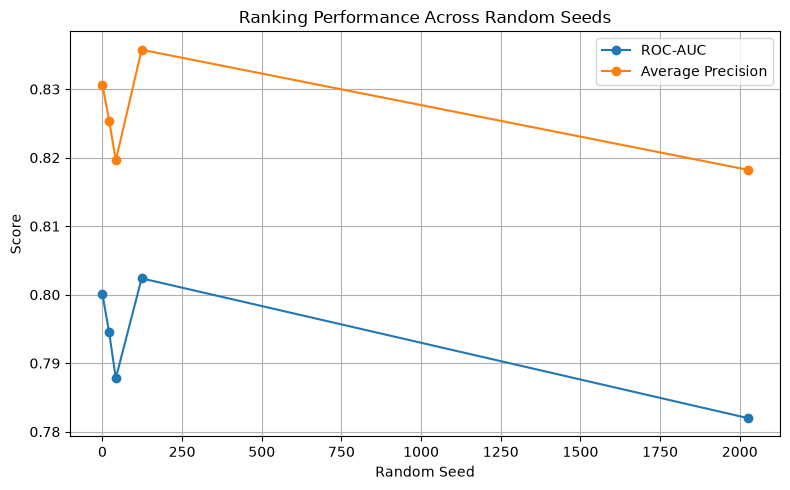

In [10]:

print("ROC-AUC")
print("Mean:", ranking_df["ROC-AUC"].mean())
print("Standard deviation:", ranking_df["ROC-AUC"].std())

print("\nAverage Precision")
print("Mean:", ranking_df["Average Precision"].mean())
print("Standard deviation:", ranking_df["Average Precision"].std())

# Plot ranking metrics across random seeds
plt.figure(figsize=(8, 5))

plt.plot(
    ranking_df["Seed"],
    ranking_df["ROC-AUC"],
    marker="o",
    label="ROC-AUC"
)

plt.plot(
    ranking_df["Seed"],
    ranking_df["Average Precision"],
    marker="o",
    label="Average Precision"
)

plt.xlabel("Random Seed")
plt.ylabel("Score")
plt.title("Ranking Performance Across Random Seeds")
plt.grid(True)
plt.legend()
plt.tight_layout()

plt.savefig(
    "ranking_metrics_robustness.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [11]:

verification_results = []
score_arrays = []

for contamination in [0.01, 0.03, 0.05, 0.10]:

    model = IsolationForest(
        n_estimators=200,
        contamination=contamination,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train)

    # Raw anomaly scores; higher means more anomalous
    scores = -model.score_samples(X_test)

    # Binary predictions using the model's threshold
    predictions = (model.predict(X_test) == -1).astype(int)

    score_arrays.append(scores)

    verification_results.append({
        "Contamination": contamination,
        "Model Threshold (offset)": model.offset_,
        "Test Alert Rate": predictions.mean(),
        "ROC-AUC": roc_auc_score(y_test, scores),
        "Average Precision": average_precision_score(y_test, scores)
    })

verification_df = pd.DataFrame(verification_results)

display(verification_df.round(4))

# Check whether score rankings are identical
for i in range(1, len(score_arrays)):
    max_difference = np.max(
        np.abs(score_arrays[0] - score_arrays[i])
    )

    print(
        f"Maximum score difference between "
        f"{[0.01, 0.03, 0.05, 0.10][0]} and "
        f"{[0.01, 0.03, 0.05, 0.10][i]}: "
        f"{max_difference:.12f}"
    )


,Contamination,Model Threshold (offset),Test Alert Rate,ROC-AUC,Average Precision
0,0.01,-0.5632,0.1165,0.7878,0.8196
1,0.03,-0.5296,0.1479,0.7878,0.8196
2,0.05,-0.5053,0.1914,0.7878,0.8196
3,0.10,-0.4729,0.3431,0.7878,0.8196


Maximum score difference between 0.01 and 0.03: 0.000000000000
Maximum score difference between 0.01 and 0.05: 0.000000000000
Maximum score difference between 0.01 and 0.1: 0.000000000000


In [12]:

from sklearn.metrics import recall_score

# Train the model at 5% contamination
category_model = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    random_state=42,
    n_jobs=-1
)

category_model.fit(X_train)

# Predict on the test dataset
category_predictions = (
    category_model.predict(X_test) == -1
).astype(int)

# Attach predictions to test records
category_analysis = test_data[["attack_cat", "label"]].copy()
category_analysis["predicted_anomaly"] = category_predictions

# Calculate detection rate for each attack category
attack_category_results = (
    category_analysis[category_analysis["label"] == 1]
    .groupby("attack_cat")
    .agg(
        Total_Records=("label", "count"),
        Detected=("predicted_anomaly", "sum")
    )
)

attack_category_results["Detection_Rate"] = (
    attack_category_results["Detected"]
    / attack_category_results["Total_Records"]
)

display(attack_category_results.sort_values(
    "Detection_Rate"
).round(4))

attack_category_results.to_csv(
    "attack_category_detection.csv"
)


,Total_Records,Detected,Detection_Rate
attack_cat,,,
Shellcode,378,0,0.0000
Reconnaissance,3496,19,0.0054
DoS,4089,157,0.0384
Analysis,677,26,0.0384
Backdoor,583,29,0.0497
Exploits,11132,624,0.0561
Fuzzers,6062,533,0.0879
Worms,44,7,0.1591
Generic,18871,12164,0.6446


In [13]:

category_seed_results = []

for seed in seeds:

    model = IsolationForest(
        n_estimators=200,
        contamination=0.05,
        random_state=seed,
        n_jobs=-1
    )

    model.fit(X_train)

    predictions = (model.predict(X_test) == -1).astype(int)

    temp = test_data[["attack_cat", "label"]].copy()
    temp["predicted_anomaly"] = predictions

    attack_only = temp[temp["label"] == 1]

    category_metrics = (
        attack_only.groupby("attack_cat")
        .agg(
            Total_Records=("label", "count"),
            Detected=("predicted_anomaly", "sum")
        )
    )

    category_metrics["Detection_Rate"] = (
        category_metrics["Detected"]
        / category_metrics["Total_Records"]
    )

    category_metrics["Seed"] = seed

    category_seed_results.append(category_metrics.reset_index())

# Combine all seeds
category_seed_df = pd.concat(
    category_seed_results,
    ignore_index=True
)

# Summarize category detection rate across seeds
category_summary = category_seed_df.groupby("attack_cat").agg(
    Total_Records=("Total_Records", "first"),
    Detection_Mean=("Detection_Rate", "mean"),
    Detection_Std=("Detection_Rate", "std")
).reset_index()

category_summary = category_summary.sort_values(
    "Detection_Mean"
)

display(category_summary.round(4))

category_seed_df.to_csv(
    "attack_category_all_seeds.csv",
    index=False
)

category_summary.to_csv(
    "attack_category_summary.csv",
    index=False
)


,attack_cat,Total_Records,Detection_Mean,Detection_Std
7,Shellcode,378,0.0005,0.0012
6,Reconnaissance,3496,0.0066,0.0019
0,Analysis,677,0.0532,0.0408
2,DoS,4089,0.0539,0.0180
3,Exploits,11132,0.0601,0.0058
1,Backdoor,583,0.0717,0.0467
4,Fuzzers,6062,0.0866,0.0089
8,Worms,44,0.1136,0.0321
5,Generic,18871,0.7113,0.0544


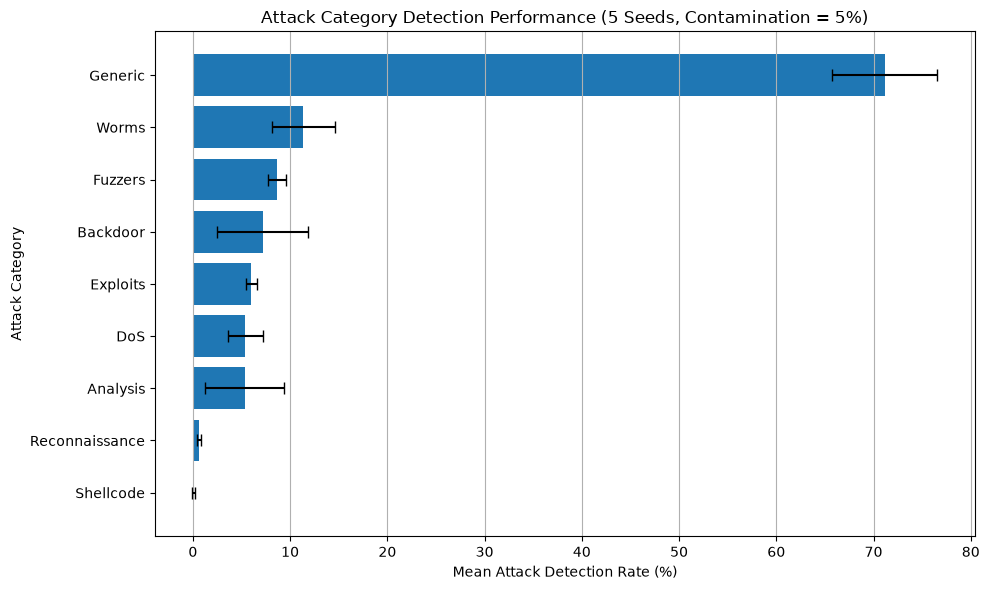

In [14]:

category_plot = category_summary.sort_values("Detection_Mean")

plt.figure(figsize=(10, 6))

plt.barh(
    category_plot["attack_cat"].astype(str),
    category_plot["Detection_Mean"] * 100,
    xerr=category_plot["Detection_Std"] * 100,
    capsize=4
)

plt.xlabel("Mean Attack Detection Rate (%)")
plt.ylabel("Attack Category")
plt.title(
    "Attack Category Detection Performance "
    "(5 Seeds, Contamination = 5%)"
)

plt.grid(axis="x")
plt.tight_layout()

plt.savefig(
    "attack_category_detection.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [15]:

# Consolidate the primary experimental results

master_results = summary_df.copy()

# Add ranking metrics (constant across contamination values)
master_results["ROC_AUC_Mean"] = ranking_df["ROC-AUC"].mean()
master_results["ROC_AUC_Std"] = ranking_df["ROC-AUC"].std()

master_results["Average_Precision_Mean"] = (
    ranking_df["Average Precision"].mean()
)

master_results["Average_Precision_Std"] = (
    ranking_df["Average Precision"].std()
)

# Rename columns for readability
master_results = master_results.rename(columns={
    "Detection_Mean": "Detection_Rate_Mean",
    "Detection_Std": "Detection_Rate_Std",
    "FPR_Mean": "False_Positive_Rate_Mean",
    "FPR_Std": "False_Positive_Rate_Std",
    "Precision_Mean": "Precision_Mean",
    "F1_Mean": "F1_Score_Mean"
})

display(master_results.round(4))

# Save master table
master_results.to_csv(
    "master_experimental_results.csv",
    index=False
)

print("Master results table saved.")


,Contamination,Detection_Rate_Mean,Detection_Rate_Std,False_Positive_Rate_Mean,False_Positive_Rate_Std,Precision_Mean,F1_Score_Mean,ROC_AUC_Mean,ROC_AUC_Std,Average_Precision_Mean,Average_Precision_Std
0,0.01,0.2163,0.0154,0.0092,0.0013,0.9664,0.3533,0.7934,0.0085,0.8259,0.0074
1,0.03,0.2601,0.0139,0.0324,0.0031,0.9078,0.4042,0.7934,0.0085,0.8259,0.0074
2,0.05,0.3297,0.0264,0.0630,0.0026,0.8649,0.4770,0.7934,0.0085,0.8259,0.0074
3,0.10,0.5297,0.0336,0.1533,0.0093,0.8088,0.6397,0.7934,0.0085,0.8259,0.0074


Master results table saved.


In [16]:

from sklearn.model_selection import train_test_split
from sklearn.ensemble import IsolationForest
from sklearn.metrics import confusion_matrix, roc_auc_score, average_precision_score
import numpy as np
import pandas as pd

target_fprs = [0.01, 0.03, 0.05, 0.10]
seeds = [0, 21, 42, 123, 2025]

threshold_transfer_results = []

for seed in seeds:

    # Split benign training data into model-fit and calibration subsets
    fit_benign, calibration_benign = train_test_split(
        train_benign,
        test_size=0.20,
        random_state=seed
    )

    # Fit preprocessing only on model-fitting benign records
    transfer_preprocessor = ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), numerical_features),
            ("cat", OneHotEncoder(handle_unknown="ignore"),
             categorical_features)
        ]
    )

    X_fit = transfer_preprocessor.fit_transform(
        fit_benign[feature_columns]
    )

    X_calibration = transfer_preprocessor.transform(
        calibration_benign[feature_columns]
    )

    X_test_transfer = transfer_preprocessor.transform(
        test_data[feature_columns]
    )

    y_test_transfer = test_data["label"].values

    # Train Isolation Forest on benign records only
    model = IsolationForest(
        n_estimators=200,
        contamination="auto",
        random_state=seed,
        n_jobs=-1
    )

    model.fit(X_fit)

    # Higher score means more anomalous
    calibration_scores = -model.score_samples(X_calibration)
    test_scores = -model.score_samples(X_test_transfer)

    for target_fpr in target_fprs:

        # Choose threshold from held-out benign calibration scores
        threshold = np.quantile(
            calibration_scores,
            1 - target_fpr
        )

        # Flag scores above the calibration threshold
        y_pred = (test_scores >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_test_transfer,
            y_pred,
            labels=[0, 1]
        ).ravel()

        actual_test_fpr = fp / (fp + tn)
        detection_rate = tp / (tp + fn)
        test_alert_rate = y_pred.mean()

        threshold_transfer_results.append({
            "Seed": seed,
            "Target_FPR": target_fpr,
            "Calibration_Threshold": threshold,
            "Test_FPR": actual_test_fpr,
            "Detection_Rate": detection_rate,
            "Test_Alert_Rate": test_alert_rate,
            "True_Negatives": tn,
            "False_Positives": fp,
            "False_Negatives": fn,
            "True_Positives": tp
        })

transfer_df = pd.DataFrame(threshold_transfer_results)

transfer_summary = transfer_df.groupby("Target_FPR").agg(
    Test_FPR_Mean=("Test_FPR", "mean"),
    Test_FPR_Std=("Test_FPR", "std"),
    Detection_Mean=("Detection_Rate", "mean"),
    Detection_Std=("Detection_Rate", "std"),
    Alert_Rate_Mean=("Test_Alert_Rate", "mean"),
    Alert_Rate_Std=("Test_Alert_Rate", "std")
).reset_index()

display(transfer_summary.round(4))

transfer_df.to_csv(
    "threshold_transfer_all_runs.csv",
    index=False
)

transfer_summary.to_csv(
    "threshold_transfer_summary.csv",
    index=False
)

print("Threshold-transfer experiment completed.")


,Target_FPR,Test_FPR_Mean,Test_FPR_Std,Detection_Mean,Detection_Std,Alert_Rate_Mean,Alert_Rate_Std
0,0.01,0.0084,0.0013,0.1823,0.0330,0.1042,0.0186
1,0.03,0.0317,0.0043,0.2499,0.0058,0.1518,0.0050
2,0.05,0.0631,0.0022,0.3080,0.0162,0.1979,0.0092
3,0.10,0.1534,0.0067,0.4979,0.0332,0.3431,0.0212


Threshold-transfer experiment completed.


In [17]:

calibration_validation = []

for seed in seeds:

    fit_benign, calibration_benign = train_test_split(
        train_benign,
        test_size=0.20,
        random_state=seed
    )

    prep = ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), numerical_features),
            ("cat", OneHotEncoder(handle_unknown="ignore"),
             categorical_features)
        ]
    )

    X_fit = prep.fit_transform(fit_benign[feature_columns])
    X_cal = prep.transform(calibration_benign[feature_columns])
    X_eval = prep.transform(test_data[feature_columns])

    model = IsolationForest(
        n_estimators=200,
        contamination="auto",
        random_state=seed,
        n_jobs=-1
    )

    model.fit(X_fit)

    cal_scores = -model.score_samples(X_cal)
    eval_scores = -model.score_samples(X_eval)

    for target in target_fprs:

        threshold = np.quantile(
            cal_scores,
            1 - target
        )

        # Actual calibration FPR
        calibration_fpr = np.mean(cal_scores >= threshold)

        # Actual test FPR
        eval_predictions = (eval_scores >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_test,
            eval_predictions,
            labels=[0, 1]
        ).ravel()

        test_fpr = fp / (fp + tn)

        calibration_validation.append({
            "Seed": seed,
            "Target_FPR": target,
            "Calibration_FPR": calibration_fpr,
            "Test_FPR": test_fpr,
            "Transfer_Gap": test_fpr - calibration_fpr
        })

validation_df = pd.DataFrame(calibration_validation)

validation_summary = validation_df.groupby("Target_FPR").agg(
    Calibration_FPR_Mean=("Calibration_FPR", "mean"),
    Test_FPR_Mean=("Test_FPR", "mean"),
    Transfer_Gap_Mean=("Transfer_Gap", "mean"),
    Transfer_Gap_Std=("Transfer_Gap", "std")
).reset_index()

display(validation_summary.round(4))

validation_df.to_csv(
    "calibration_validation_all_runs.csv",
    index=False
)

validation_summary.to_csv(
    "calibration_validation_summary.csv",
    index=False
)


,Target_FPR,Calibration_FPR_Mean,Test_FPR_Mean,Transfer_Gap_Mean,Transfer_Gap_Std
0,0.01,0.0100,0.0084,-0.0016,0.0013
1,0.03,0.0301,0.0317,0.0016,0.0042
2,0.05,0.0500,0.0631,0.0131,0.0022
3,0.10,0.1000,0.1534,0.0534,0.0067


In [18]:

from scipy.stats import ks_2samp

ks_results = []

for seed in seeds:

    fit_benign, calibration_benign = train_test_split(
        train_benign,
        test_size=0.20,
        random_state=seed
    )

    prep = ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), numerical_features),
            ("cat", OneHotEncoder(handle_unknown="ignore"),
             categorical_features)
        ]
    )

    X_fit = prep.fit_transform(fit_benign[feature_columns])
    X_cal = prep.transform(calibration_benign[feature_columns])
    X_eval = prep.transform(test_data[feature_columns])

    model = IsolationForest(
        n_estimators=200,
        contamination="auto",
        random_state=seed,
        n_jobs=-1
    )

    model.fit(X_fit)

    calibration_scores = -model.score_samples(X_cal)

    # Select only genuinely benign test observations
    benign_test_mask = (y_test == 0)
    X_benign_test = X_eval[benign_test_mask]

    benign_test_scores = -model.score_samples(X_benign_test)

    ks_stat, p_value = ks_2samp(
        calibration_scores,
        benign_test_scores
    )

    ks_results.append({
        "Seed": seed,
        "KS_Statistic": ks_stat,
        "P_Value": p_value,
        "Calibration_Median": np.median(calibration_scores),
        "Test_Benign_Median": np.median(benign_test_scores)
    })

ks_df = pd.DataFrame(ks_results)

display(ks_df.round(6))

print("\nMean KS statistic:", ks_df["KS_Statistic"].mean())
print("Mean calibration median:", ks_df["Calibration_Median"].mean())
print("Mean test benign median:", ks_df["Test_Benign_Median"].mean())

ks_df.to_csv("ks_distribution_comparison.csv", index=False)


,Seed,KS_Statistic,P_Value,Calibration_Median,Test_Benign_Median
0,0,0.093911,0.0,0.392887,0.399156
1,21,0.107765,0.0,0.399635,0.407655
2,42,0.103478,0.0,0.397187,0.403472
3,123,0.107687,0.0,0.397448,0.404693
4,2025,0.101395,0.0,0.403051,0.408198



Mean KS statistic: 0.10284749034749034
Mean calibration median: 0.3980417572339924
Mean test benign median: 0.40463477538877013


In [19]:
import sys
import sklearn
import pandas
import numpy
import scipy

print("Python:", sys.version)
print("Scikit-learn:", sklearn.__version__)
print("Pandas:", pandas.__version__)
print("NumPy:", numpy.__version__)
print("SciPy:", scipy.__version__)

Python: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
Scikit-learn: 1.9.1
Pandas: 3.1.1
NumPy: 2.4.6
SciPy: 1.17.1
